<a href="https://colab.research.google.com/github/pradip4422/COFFE-SHOP/blob/main/big_data_analyst.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install -q pyspark pandas matplotlib seaborn
print("Installation finished.")

Installation finished.


In [7]:
import os, re, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import NumericType
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.stat import Correlation

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.1)

OUTPUT_DIR = "/content/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Libraries imported. Output folder:", OUTPUT_DIR)

Libraries imported. Output folder: /content/outputs


In [8]:
try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No file was uploaded. Re-run this cell and choose the CSV file.")
    CSV_PATH = list(uploaded.keys())[0]
except ImportError:
    CSV_PATH = input("Not running in Colab. Enter the CSV file path: ").strip()

print("Using file:", CSV_PATH)

Saving crop_yield.csv to crop_yield.csv
Using file: crop_yield.csv


In [9]:
try:
    spark = (SparkSession.builder
             .master("local[*]")
             .appName("CropYield_FA2")
             .config("spark.driver.memory", "4g")
             .config("spark.sql.shuffle.partitions", "8")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    print("Spark version:", spark.version)
except Exception as e:
    print("Could not start Spark. Run Cell 1 again, then Runtime > Restart session.")
    raise e

Spark version: 4.0.4


In [10]:
try:
    df = spark.read.csv(CSV_PATH, header=True, inferSchema=True)
except Exception as e:
    print("Could not read the CSV. Check that the file is a valid CSV.")
    raise e

for c in df.columns:
    df = df.withColumnRenamed(c, re.sub(r"\W+", "_", c.strip()).strip("_"))

_lookup = {c.lower(): c for c in df.columns}
def pick(*names):
    for n in names:
        if n.lower() in _lookup:
            return _lookup[n.lower()]
    return None

CROP   = pick("Crop")
YEAR   = pick("Crop_Year", "Year")
SEASON = pick("Season")
STATE  = pick("State")
AREA   = pick("Area")
PROD   = pick("Production")
RAIN   = pick("Annual_Rainfall", "Rainfall")
FERT   = pick("Fertilizer")
PEST   = pick("Pesticide")
YIELD  = pick("Yield")

print("Columns found in your file:", df.columns)
print({"Crop": CROP, "Year": YEAR, "Season": SEASON, "State": STATE, "Area": AREA,
       "Production": PROD, "Rainfall": RAIN, "Fertilizer": FERT, "Pesticide": PEST, "Yield": YIELD})

if YIELD is None and not (PROD and AREA):
    raise ValueError("No Yield column, and Production/Area are not both available to derive it.")

Columns found in your file: ['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']
{'Crop': 'Crop', 'Year': 'Crop_Year', 'Season': 'Season', 'State': 'State', 'Area': 'Area', 'Production': 'Production', 'Rainfall': 'Annual_Rainfall', 'Fertilizer': 'Fertilizer', 'Pesticide': 'Pesticide', 'Yield': 'Yield'}


In [11]:
print("=== SCHEMA ===")
df.printSchema()

print("=== FIRST 5 ROWS ===")
df.show(5, truncate=False)

total_rows = df.count()
print("=== TOTAL RECORDS ===", total_rows)

print("=== MISSING VALUES PER COLUMN ===")
exprs = []
for f in df.schema.fields:
    c = F.col(f.name)
    cond = c.isNull()
    if isinstance(f.dataType, NumericType):
        cond = cond | F.isnan(c)
    else:
        cond = cond | (F.trim(c) == "")
    exprs.append(F.sum(F.when(cond, 1).otherwise(0)).alias(f.name))
df.agg(*exprs).show(truncate=False)

dup_count = total_rows - df.dropDuplicates().count()
print("=== DUPLICATE RECORDS ===", dup_count)

=== SCHEMA ===
root
 |-- Crop: string (nullable = true)
 |-- Crop_Year: integer (nullable = true)
 |-- Season: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Area: double (nullable = true)
 |-- Production: long (nullable = true)
 |-- Annual_Rainfall: double (nullable = true)
 |-- Fertilizer: double (nullable = true)
 |-- Pesticide: double (nullable = true)
 |-- Yield: double (nullable = true)

=== FIRST 5 ROWS ===
+------------+---------+-----------+-----+-------+----------+---------------+----------+---------+-----------+
|Crop        |Crop_Year|Season     |State|Area   |Production|Annual_Rainfall|Fertilizer|Pesticide|Yield      |
+------------+---------+-----------+-----+-------+----------+---------------+----------+---------+-----------+
|Arecanut    |1997     |Whole Year |Assam|73814.0|56708     |2051.4         |7024878.38|22882.34 |0.796086957|
|Arhar/Tur   |1997     |Kharif     |Assam|6637.0 |4685      |2051.4         |631643.29 |2057.47  |0.710434783|
|Castor

In [12]:
YIELD_CAP_PERCENTILE = 0.995   # outlier removal band karaycha asel tar None kara

cat_cols = [c for c in [CROP, SEASON, STATE] if c]
numeric_cols = [c for c in [YEAR, AREA, PROD, RAIN, FERT, PEST, YIELD] if c]

df_clean = df
rows_start = df_clean.count()

for c in cat_cols:
    df_clean = df_clean.withColumn(c, F.trim(F.col(c)))
    df_clean = df_clean.withColumn(c, F.when(F.col(c).isNull() | (F.col(c) == ""), "Unknown").otherwise(F.col(c)))

for c in numeric_cols:
    df_clean = df_clean.withColumn(c, F.col(c).cast("double"))
    df_clean = df_clean.withColumn(c, F.when(F.isnan(F.col(c)), None).otherwise(F.col(c)))

if YIELD is None:
    df_clean = df_clean.withColumn("Yield", F.col(PROD) / F.col(AREA))
    YIELD = "Yield"
    numeric_cols.append("Yield")
    print("Yield column created as Production / Area.")

df_clean = df_clean.dropDuplicates()

for c in [RAIN, FERT, PEST]:
    if c:
        df_clean = df_clean.withColumn(c, F.when(F.col(c) < 0, None).otherwise(F.col(c)))

required = [c for c in [YIELD, AREA] if c]
df_clean = df_clean.dropna(subset=required).filter(F.col(YIELD) > 0)
if AREA:
    df_clean = df_clean.filter(F.col(AREA) > 0)

FEATURE_NUM = [c for c in [YEAR, AREA, RAIN, FERT, PEST] if c]
for c in FEATURE_NUM:
    if c not in required:
        med = df_clean.approxQuantile(c, [0.5], 0.01)
        if med:
            df_clean = df_clean.fillna({c: med[0]})
FEATURE_CAT = cat_cols

if YIELD_CAP_PERCENTILE:
    cap = df_clean.approxQuantile(YIELD, [YIELD_CAP_PERCENTILE], 0.001)[0]
    before = df_clean.count()
    df_clean = df_clean.filter(F.col(YIELD) <= cap)
    print(f"Outlier cap: removed {before - df_clean.count()} rows with Yield > {cap:.4f}")

df_clean = df_clean.cache()
print("Rows before cleaning:", rows_start)
print("Rows after cleaning :", df_clean.count())
df_clean.show(5, truncate=False)

Outlier cap: removed 117 rows with Yield > 6475.4641
Rows before cleaning: 19689
Rows after cleaning : 19460
+------------+---------+----------+---------+--------+----------+---------------+-------------+---------+-----------+
|Crop        |Crop_Year|Season    |State    |Area    |Production|Annual_Rainfall|Fertilizer   |Pesticide|Yield      |
+------------+---------+----------+---------+--------+----------+---------------+-------------+---------+-----------+
|Jute        |1997.0   |Kharif    |Assam    |94520.0 |904095.0  |2051.4         |8995468.4    |29301.2  |9.919565217|
|Mesta       |1997.0   |Kharif    |Assam    |5915.0  |29003.0   |2051.4         |562930.55    |1833.65  |4.568947368|
|Potato      |1997.0   |Whole Year|Assam    |75259.0 |671871.0  |2051.4         |7162399.03   |23330.29 |7.561304348|
|Dry chillies|1997.0   |Rabi      |Karnataka|4565.0  |7895.0    |1266.7         |434451.05    |1415.15  |1.869444444|
|Groundnut   |1997.0   |Rabi      |Karnataka|192416.0|181071.0  |

In [13]:
print("=== SUMMARY STATISTICS ===")
df_clean.select(*numeric_cols).describe().show(truncate=False)

for c in cat_cols:
    print(f"=== Number of distinct {c} values:", df_clean.select(c).distinct().count())

if CROP:
    print("=== Records per crop (top 10) ===")
    df_clean.groupBy(CROP).count().orderBy(F.desc("count")).show(10, truncate=False)
if SEASON:
    print("=== Average yield by season ===")
    df_clean.groupBy(SEASON).agg(F.round(F.avg(YIELD), 3).alias("avg_yield"), F.count("*").alias("records")) \
            .orderBy(F.desc("avg_yield")).show(truncate=False)
if STATE:
    print("=== Average yield by state (top 10) ===")
    df_clean.groupBy(STATE).agg(F.round(F.avg(YIELD), 3).alias("avg_yield"), F.count("*").alias("records")) \
            .orderBy(F.desc("avg_yield")).show(10, truncate=False)
if YEAR:
    print("=== Year range ===")
    df_clean.agg(F.min(YEAR).alias("first_year"), F.max(YEAR).alias("last_year")).show()

=== SUMMARY STATISTICS ===
+-------+------------------+-----------------+--------------------+------------------+-------------------+------------------+-----------------+
|summary|Crop_Year         |Area             |Production          |Annual_Rainfall   |Fertilizer         |Pesticide         |Yield            |
+-------+------------------+-----------------+--------------------+------------------+-------------------+------------------+-----------------+
|count  |19460             |19460            |19460               |19460             |19460              |19460             |19460            |
|mean   |2009.1129496402878|180827.2830173176|5420311.256012333   |1437.9757272321228|2.420801656392441E7|49093.51689004982 |17.2051483505795 |
|stddev |6.503497486471345 |736741.880573491 |1.4635306360538232E8|817.5154889977323 |9.543898666483358E7|214434.20277755798|262.2707280921983|
|min    |1997.0            |0.5              |0.0                 |301.3             |54.17              |0.0

In [14]:
show_cols = [c for c in [CROP, STATE, SEASON, YEAR, AREA, RAIN, YIELD] if c]

print("=== Records with above-average yield (sample) ===")
avg_yield_value = df_clean.agg(F.avg(YIELD)).first()[0]
high_yield = df_clean.filter(F.col(YIELD) > avg_yield_value).select(*show_cols)
print("Average yield:", round(avg_yield_value, 4))
print("Number of above-average records (count action):", high_yield.count())
high_yield.show(5, truncate=False)

df_analysis = df_clean
if FERT and AREA:
    df_analysis = df_analysis.withColumn("Fertilizer_per_Area", F.col(FERT) / F.col(AREA))
if PEST and AREA:
    df_analysis = df_analysis.withColumn("Pesticide_per_Area", F.col(PEST) / F.col(AREA))
if RAIN:
    q1, q2 = df_analysis.approxQuantile(RAIN, [0.33, 0.66], 0.01)
    df_analysis = df_analysis.withColumn(
        "Rainfall_Category",
        F.when(F.col(RAIN) < q1, "Low").when(F.col(RAIN) < q2, "Medium").otherwise("High"))
    print("=== Average yield by rainfall category ===")
    df_analysis.groupBy("Rainfall_Category").agg(
        F.count("*").alias("records"),
        F.round(F.avg(YIELD), 3).alias("avg_yield")).orderBy("Rainfall_Category").show()

if CROP:
    print("=== Crop-wise yield summary (top 10 by average yield) ===")
    df_analysis.groupBy(CROP).agg(
        F.count("*").alias("records"),
        F.round(F.avg(YIELD), 3).alias("avg_yield"),
        F.round(F.max(YIELD), 3).alias("max_yield"),
        F.round(F.min(YIELD), 3).alias("min_yield")).orderBy(F.desc("avg_yield")).show(10, truncate=False)

if YEAR:
    print("=== Year-wise average yield ===")
    df_analysis.groupBy(YEAR).agg(F.round(F.avg(YIELD), 3).alias("avg_yield"), F.count("*").alias("records")) \
               .orderBy(YEAR).show(40)

=== Records with above-average yield (sample) ===
Average yield: 17.2051
Number of above-average records (count action): 1081
+---------+--------------+----------+---------+--------+---------------+-----------+
|Crop     |State         |Season    |Crop_Year|Area    |Annual_Rainfall|Yield      |
+---------+--------------+----------+---------+--------+---------------+-----------+
|Coconut  |Assam         |Whole Year|1998.0   |20166.0 |2354.4         |6045.886957|
|Sugarcane|West Bengal   |Whole Year|1998.0   |26949.0 |2152.5         |75.314375  |
|Tapioca  |Puducherry    |Whole Year|1999.0   |365.0   |1434.5875      |18.29      |
|Sugarcane|Andhra Pradesh|Whole Year|2000.0   |237150.0|935.6          |73.8955    |
|Banana   |Karnataka     |Whole Year|2000.0   |35335.0 |1213.3         |18.36037037|
+---------+--------------+----------+---------+--------+---------------+-----------+
only showing top 5 rows
=== Average yield by rainfall category ===
+-----------------+-------+---------+
|Rai

In [15]:
TARGET = YIELD
leak_note = [c for c in [PROD] if c]
print("Target:", TARGET)
print("Numeric features:", FEATURE_NUM)
print("Categorical features:", FEATURE_CAT)
print("Excluded to avoid leakage:", leak_note)

if not FEATURE_NUM and not FEATURE_CAT:
    raise ValueError("No usable input features found.")

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}__idx", handleInvalid="keep") for c in FEATURE_CAT]
encoder = OneHotEncoder(inputCols=[f"{c}__idx" for c in FEATURE_CAT],
                        outputCols=[f"{c}__ohe" for c in FEATURE_CAT],
                        handleInvalid="keep") if FEATURE_CAT else None
assembler = VectorAssembler(inputCols=FEATURE_NUM + [f"{c}__ohe" for c in FEATURE_CAT],
                            outputCol="features", handleInvalid="skip")
rf = RandomForestRegressor(featuresCol="features", labelCol=TARGET, predictionCol="prediction",
                           numTrees=100, maxDepth=10, seed=42)

stages = indexers + ([encoder] if encoder else []) + [assembler, rf]
pipeline = Pipeline(stages=stages)

train_df, test_df = df_clean.randomSplit([0.8, 0.2], seed=42)
print("Training rows:", train_df.count(), "| Testing rows:", test_df.count())

try:
    model = pipeline.fit(train_df)
    predictions = model.transform(test_df)
    print("Model trained successfully.")
except Exception as e:
    print("Training failed. Re-run Cells 5 to 9 in order, or restart the session.")
    raise e

Target: Yield
Numeric features: ['Crop_Year', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']
Categorical features: ['Crop', 'Season', 'State']
Excluded to avoid leakage: ['Production']
Training rows: 15688 | Testing rows: 3772
Model trained successfully.


In [16]:
def metric(name):
    return RegressionEvaluator(labelCol=TARGET, predictionCol="prediction", metricName=name).evaluate(predictions)

mae, rmse, r2 = metric("mae"), metric("rmse"), metric("r2")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

train_mean = train_df.agg(F.avg(TARGET)).first()[0]
baseline_rmse = (test_df.withColumn("b", F.pow(F.col(TARGET) - F.lit(train_mean), 2))
                 .agg(F.sqrt(F.avg("b"))).first()[0])
print(f"Baseline RMSE (predict the mean): {baseline_rmse:.4f}")

importance_df = None
try:
    attrs = predictions.schema["features"].metadata["ml_attr"]["attrs"]
    names = {}
    for group in attrs.values():
        for a in group:
            names[a["idx"]] = a["name"]
    imps = model.stages[-1].featureImportances.toArray()
    rows = {}
    for i, v in enumerate(imps):
        n = names.get(i, f"f{i}")
        key = next((c for c in FEATURE_CAT if n.startswith(f"{c}__ohe")), n)
        rows[key] = rows.get(key, 0.0) + float(v)
    importance_df = (pd.DataFrame({"Feature": list(rows), "Importance": list(rows.values())})
                     .sort_values("Importance", ascending=False).reset_index(drop=True))
    print("\nFeature importance:")
    print(importance_df.to_string(index=False))
except Exception as e:
    print("Feature importance could not be extracted:", e)

MAE  : 2.5809
RMSE : 17.1651
R²   : 0.9952
Baseline RMSE (predict the mean): 246.6697

Feature importance:
        Feature  Importance
           Crop    0.791088
     Fertilizer    0.042980
           Area    0.041757
          State    0.041391
Annual_Rainfall    0.028896
      Pesticide    0.025243
         Season    0.022246
      Crop_Year    0.006399


In [17]:
keep = [c for c in [CROP, STATE, SEASON, YEAR, AREA, RAIN] if c]
pred_spark = (predictions.select(*keep, F.col(TARGET).alias("Actual_Yield"), F.col("prediction").alias("Predicted_Yield"))
              .withColumn("Absolute_Error", F.abs(F.col("Actual_Yield") - F.col("Predicted_Yield")))
              .withColumn("Predicted_Yield", F.round("Predicted_Yield", 4))
              .withColumn("Absolute_Error", F.round("Absolute_Error", 4)))

print("=== Sample predictions ===")
pred_spark.show(15, truncate=False)

pred_pd = pred_spark.toPandas()
pred_csv = os.path.join(OUTPUT_DIR, "crop_yield_predictions.csv")
pred_pd.to_csv(pred_csv, index=False)
print("Saved:", pred_csv, "| rows:", len(pred_pd))

=== Sample predictions ===
+---------+--------------+----------+---------+--------+---------------+------------+---------------+--------------+
|Crop     |State         |Season    |Crop_Year|Area    |Annual_Rainfall|Actual_Yield|Predicted_Yield|Absolute_Error|
+---------+--------------+----------+---------+--------+---------------+------------+---------------+--------------+
|Arecanut |Meghalaya     |Whole Year|1998.0   |9585.0  |6552.7         |1.151666667 |3.695          |2.5433        |
|Arecanut |Goa           |Whole Year|2003.0   |1600.0  |3011.6         |1.66        |2.6116         |0.9516        |
|Arecanut |Andhra Pradesh|Whole Year|2006.0   |255.0   |845.2          |0.685       |3.7941         |3.1091        |
|Arecanut |Tamil Nadu    |Whole Year|2009.0   |5456.0  |928.5          |1.605       |3.861          |2.256         |
|Arecanut |Karnataka     |Whole Year|2015.0   |247927.0|1024.9         |10.21047619 |48.9312        |38.7208       |
|Arecanut |Karnataka     |Whole Year|

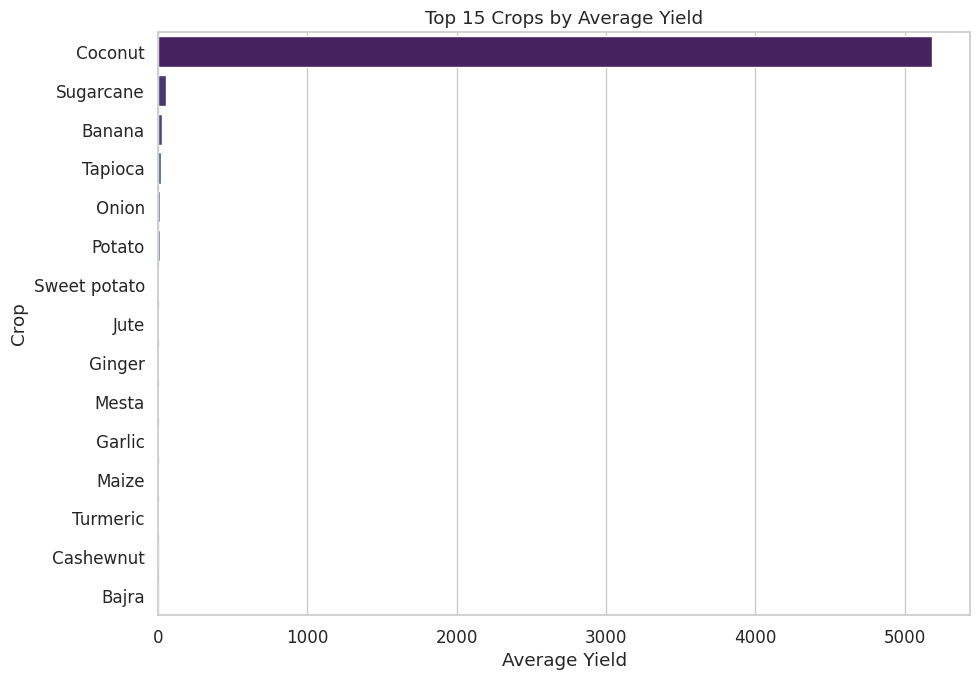

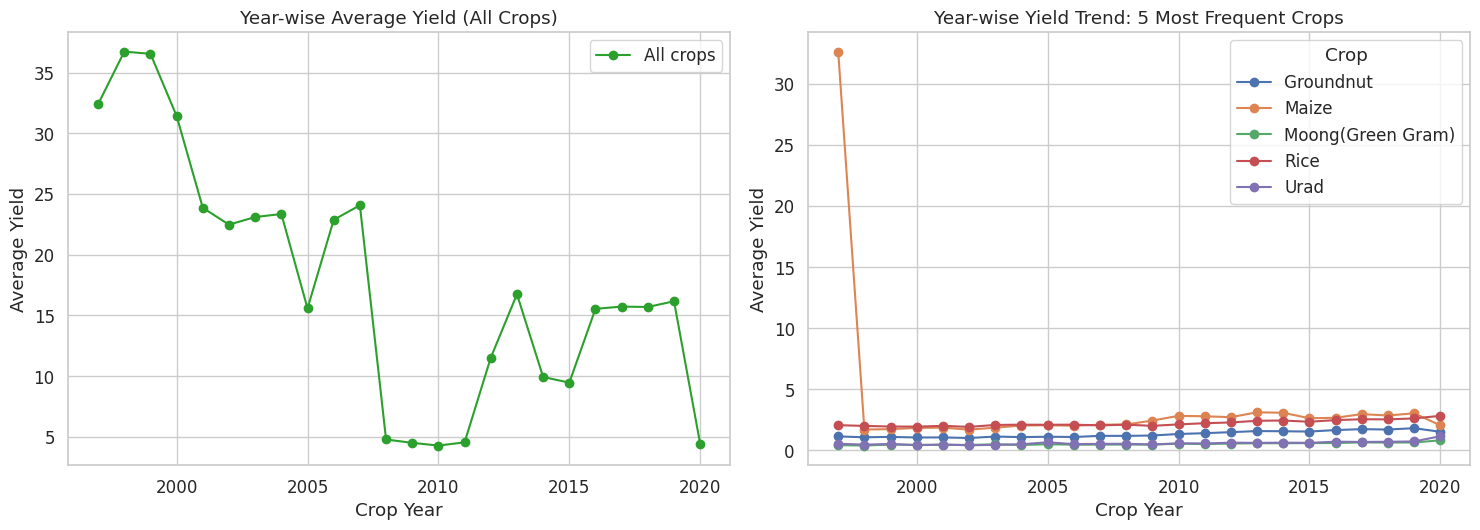

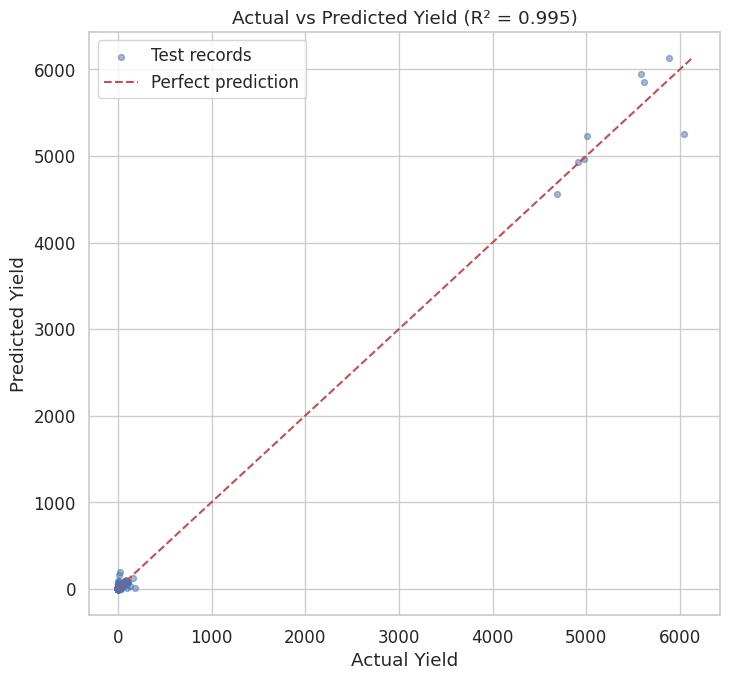

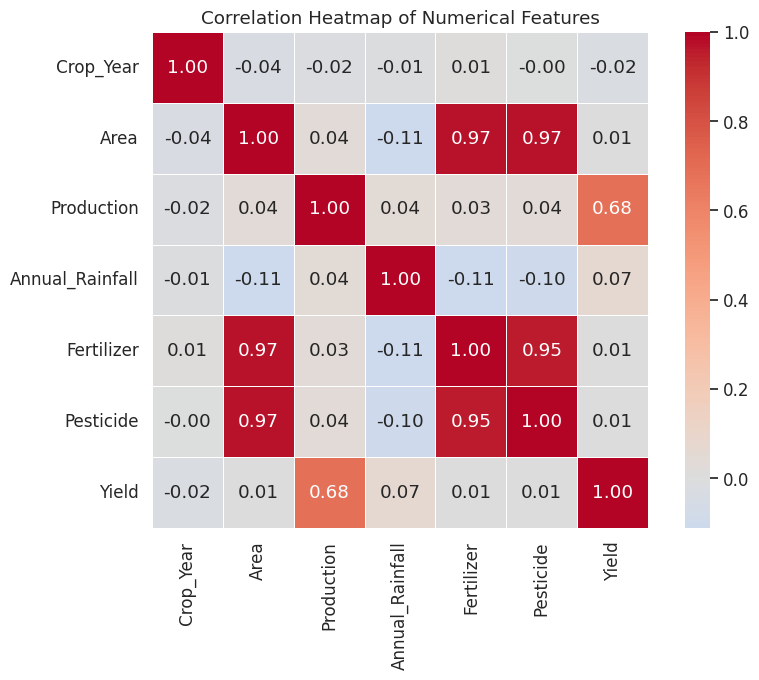

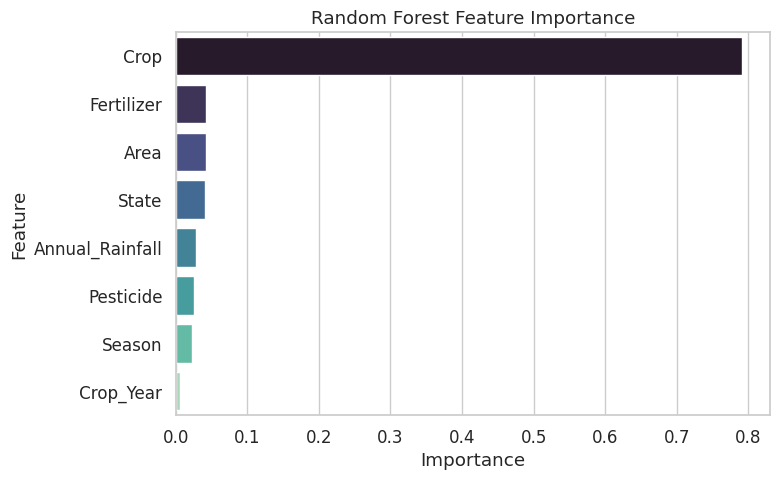

Saved charts: ['1_bar_avg_yield_by_crop.png', '2_line_yearwise_yield_trend.png', '3_scatter_actual_vs_predicted.png', '4_heatmap_correlation.png', '5_feature_importance.png']


In [18]:
saved_charts = []
def save_fig(name):
    path = os.path.join(OUTPUT_DIR, name)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    saved_charts.append(path)
    plt.show()

# Chart 1: Bar chart, average yield by crop
if CROP:
    crop_avg = (df_clean.groupBy(CROP).agg(F.avg(YIELD).alias("avg_yield"), F.count("*").alias("n"))
                .orderBy(F.desc("avg_yield")).limit(15).toPandas())
    plt.figure(figsize=(10, 7))
    sns.barplot(data=crop_avg, x="avg_yield", y=CROP, hue=CROP, palette="viridis", legend=False)
    plt.title("Top 15 Crops by Average Yield")
    plt.xlabel("Average Yield")
    plt.ylabel("Crop")
    save_fig("1_bar_avg_yield_by_crop.png")

# Chart 2: Line chart, year-wise yield trends
if YEAR:
    year_avg = df_clean.groupBy(YEAR).agg(F.avg(YIELD).alias("avg_yield")).orderBy(YEAR).toPandas()
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    axes[0].plot(year_avg[YEAR], year_avg["avg_yield"], marker="o", color="tab:green", label="All crops")
    axes[0].set_title("Year-wise Average Yield (All Crops)")
    axes[0].set_xlabel("Crop Year")
    axes[0].set_ylabel("Average Yield")
    axes[0].legend()
    if CROP:
        top5 = [r[CROP] for r in df_clean.groupBy(CROP).count().orderBy(F.desc("count")).limit(5).collect()]
        trend = (df_clean.filter(F.col(CROP).isin(top5)).groupBy(YEAR, CROP)
                 .agg(F.avg(YIELD).alias("avg_yield")).orderBy(YEAR).toPandas())
        for crop_name, g in trend.groupby(CROP):
            axes[1].plot(g[YEAR], g["avg_yield"], marker="o", label=crop_name)
        axes[1].set_title("Year-wise Yield Trend: 5 Most Frequent Crops")
        axes[1].set_xlabel("Crop Year")
        axes[1].set_ylabel("Average Yield")
        axes[1].legend(title="Crop")
    save_fig("2_line_yearwise_yield_trend.png")

# Chart 3: Scatter, actual vs predicted
sample = pred_pd.sample(min(5000, len(pred_pd)), random_state=42)
lo, hi = float(min(sample["Actual_Yield"].min(), sample["Predicted_Yield"].min())), \
         float(max(sample["Actual_Yield"].max(), sample["Predicted_Yield"].max()))
plt.figure(figsize=(7.5, 7))
plt.scatter(sample["Actual_Yield"], sample["Predicted_Yield"], alpha=0.5, s=18, label="Test records")
plt.plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
plt.title(f"Actual vs Predicted Yield (R² = {r2:.3f})")
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.legend()
save_fig("3_scatter_actual_vs_predicted.png")

# Chart 4: Correlation heatmap
corr_cols = [c for c in numeric_cols if df_clean.select(c).distinct().count() > 1]
vec = VectorAssembler(inputCols=corr_cols, outputCol="corr_features", handleInvalid="skip").transform(df_clean)
corr_matrix = Correlation.corr(vec, "corr_features", "pearson").head()[0].toArray()
corr_pd = pd.DataFrame(corr_matrix, index=corr_cols, columns=corr_cols)
plt.figure(figsize=(9, 7))
sns.heatmap(corr_pd, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
save_fig("4_heatmap_correlation.png")

# Chart 5 (extra): Feature importance
if importance_df is not None and len(importance_df):
    plt.figure(figsize=(8, 5))
    sns.barplot(data=importance_df, x="Importance", y="Feature", hue="Feature", palette="mako", legend=False)
    plt.title("Random Forest Feature Importance")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    save_fig("5_feature_importance.png")

print("Saved charts:", [os.path.basename(p) for p in saved_charts])

In [19]:
zip_path = shutil.make_archive("/content/FA2_outputs", "zip", OUTPUT_DIR)
print("Files in output folder:", os.listdir(OUTPUT_DIR))
try:
    from google.colab import files
    files.download(zip_path)
    files.download(pred_csv)
except ImportError:
    print("Not in Colab. Find your files at:", OUTPUT_DIR)

Files in output folder: ['1_bar_avg_yield_by_crop.png', '2_line_yearwise_yield_trend.png', 'crop_yield_predictions.csv', '4_heatmap_correlation.png', '5_feature_importance.png', '3_scatter_actual_vs_predicted.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
lines = []
lines.append(f"Dataset after cleaning: {df_clean.count()} records; training {train_df.count()}, testing {test_df.count()}.")
if CROP:
    best, worst = crop_avg.iloc[0], crop_avg.iloc[-1]
    lines.append(f"Highest average yield among the top-15 crops shown: {best[CROP]} ({best['avg_yield']:.2f}); lowest of those 15: {worst[CROP]} ({worst['avg_yield']:.2f}).")
if YEAR:
    yb = year_avg.loc[year_avg['avg_yield'].idxmax()]
    yl = year_avg.loc[year_avg['avg_yield'].idxmin()]
    lines.append(f"Years covered: {int(year_avg[YEAR].min())} to {int(year_avg[YEAR].max())}. Highest average yield in {int(yb[YEAR])} ({yb['avg_yield']:.2f}); lowest in {int(yl[YEAR])} ({yl['avg_yield']:.2f}).")
if YIELD in corr_pd.index:
    yc = corr_pd[YIELD].drop(YIELD).sort_values(key=abs, ascending=False)
    if len(yc):
        lines.append("Strongest linear correlations with yield: " + ", ".join(f"{k} ({v:+.2f})" for k, v in yc.head(3).items()) + ".")
lines.append(f"Random Forest results on test data: MAE = {mae:.4f}, RMSE = {rmse:.4f}, R2 = {r2:.4f}.")
lines.append(f"A baseline that always predicts the mean yield has RMSE = {baseline_rmse:.4f}; the model's RMSE is {'lower' if rmse < baseline_rmse else 'not lower'} than this baseline ({(1 - rmse / baseline_rmse) * 100:.1f}% change).")
if importance_df is not None and len(importance_df):
    lines.append("Most important features for the model: " + ", ".join(f"{r.Feature} ({r.Importance:.2f})" for r in importance_df.head(3).itertuples()) + ".")
if YIELD_CAP_PERCENTILE:
    lines.append(f"Note: the top {round((1 - YIELD_CAP_PERCENTILE) * 100, 2)}% of yield values were removed as outliers before modelling.")

print("FINDINGS (from actual output)")
print("-" * 60)
for i, l in enumerate(lines, 1):
    print(f"{i}. {l}")
print("-" * 60)

FINDINGS (from actual output)
------------------------------------------------------------
1. Dataset after cleaning: 19460 records; training 15688, testing 3772.
2. Highest average yield among the top-15 crops shown: Coconut (5182.12); lowest of those 15: Bajra (2.43).
3. Years covered: 1997 to 2020. Highest average yield in 1998 (36.73); lowest in 2010 (4.29).
4. Strongest linear correlations with yield: Production (+0.68), Annual_Rainfall (+0.07), Crop_Year (-0.02).
5. Random Forest results on test data: MAE = 2.5809, RMSE = 17.1651, R2 = 0.9952.
6. A baseline that always predicts the mean yield has RMSE = 246.6697; the model's RMSE is lower than this baseline (93.0% change).
7. Most important features for the model: Crop (0.79), Fertilizer (0.04), Area (0.04).
8. Note: the top 0.5% of yield values were removed as outliers before modelling.
------------------------------------------------------------
